# cardioEnrich demo — `rule:cardio-v0.1`

Deterministic cardiovascular evidence extraction over real ProteomeXchange
records — the domain-layer port of **pxEnrich**. Runs fully offline on the
bundled seed snapshot; the engine is stdlib-only (pandas is used here only to
display tables).

The rule diff against pxEnrich `rule:v0.1` is in `docs/RULES_DIFF.md`.
Non-diagnostic research-metadata tool.

In [1]:
import json
import pandas as pd

from cardioenrich.models import DatasetRecord
from cardioenrich.extraction import RULE_VERSION, enrich_record

with open("data/seed/cardio_seed_datasets.json", encoding="utf-8") as f:
    payload = json.load(f)

allowed = set(DatasetRecord.__dataclass_fields__)
records = [enrich_record(DatasetRecord(**{k: v for k, v in d.items() if k in allowed}))
           for d in payload["datasets"]]
print(RULE_VERSION, "—", len(records), "records "
      f"({sum(r.synthetic for r in records)} synthetic, flagged)")
print("Snapshot retrieved:", payload["retrieved"])

rule:cardio-v0.1 — 12 records (2 synthetic, flagged)
Snapshot retrieved: 2026-10-30


## 1. Every field gets an answer — and a non-answer is an answer

One row per (record × field). `unknown`, `abstained`, `mixed`, and
`conflicting` are first-class statuses: the engine never confuses
*we did not look* with *we looked and found nothing*, and never papers over a
disagreement.

In [2]:
rows = [a.to_dict() for r in records for a in r.assertions]
df = pd.DataFrame(rows)[["dataset_accession", "field", "status", "value",
                         "evidence_text", "scope", "note"]]
df.status.value_counts().to_frame("count")

,count
status,
unknown,84
asserted,38
abstained,5
mixed,3
conflicting,2


In [3]:
# All non-unknown findings, with their evidence snippets:
pd.set_option("display.max_colwidth", 90)
df[df.status != "unknown"][["dataset_accession", "field", "status", "value",
                            "evidence_text"]].reset_index(drop=True)

,dataset_accession,field,status,value,evidence_text
0,PXD018678,organism_context,asserted,human — patient/donor-derived samples,Proteomic analysis of ischemic and dilated cardiomyopathy pre-mortem human hearts\n\ni...
1,PXD018678,disease_context,asserted,cardiomyopathy — dilated (DCM),Proteomic analysis of ischemic and dilated cardiomyopathy pre-mortem human hearts
2,PXD018678,etiology,mixed,"dilated (DCM), ischemic (ICM)",'dilated cardiomyopathy'; 'ischemic cardiomyopathy'
3,PXD018678,cardiac_region,asserted,myocardium (chamber unspecified),"…omyopathy pre-mortem human hearts\n\nischemic cardiomyopathy, myocardium, dilated car..."
4,PXD018678,sample_type,asserted,cardiac tissue,Proteomic analysis of ischemic and dilated cardiomyopathy pre-mortem human hearts
5,PXD046631,organism_context,asserted,animal model (mouse),Species field: Mus musculus
6,PXD046631,disease_context,asserted,ischemia–reperfusion injury,Lysine lactylation of mouse ischemia reperfusion heart
7,PXD046631,model_system,asserted,ischemia–reperfusion,"Lysine lactylation of mouse ischemia reperfusion heart\n\nheart, mouse, Lysine lactyla..."
8,PXD017765,organism_context,asserted,animal model (rat),Species field: Rattus norvegicus
9,PXD017765,disease_context,abstained,NaN,"Rats, heart tissue, iTRAQ proteomics"


## 2. The derivation rules in action (D1–D5)

**D1** — a stated LVEF is banded by the 2021 Universal Definition
(HFrEF ≤40 %, HFmrEF 41–49 %, HFpEF ≥50 %; named simplification).
**D4** — when the stated term and the stated EF disagree, the answer is
`conflicting`, with both evidences attached — never a silent resolution.

In [4]:
for acc, fld in (("CARDIO-DEMO-0001", "hf_subtype"),
                 ("CARDIO-DEMO-0002", "hf_subtype"),
                 ("PXD047728", "organism_context")):
    rec = next(r for r in records if r.accession == acc)
    a = next(x for x in rec.assertions if x.field == fld)
    print(f"— {acc}" + ("  [SYNTHETIC]" if rec.synthetic else "  [real record]"))
    print(f"  {a.field}: {a.status.value.upper()}  value={a.value!r}")
    print(f"  evidence: {a.evidence_text}")
    print(f"  note: {a.note}")
    print()

— CARDIO-DEMO-0001  [SYNTHETIC]
  hf_subtype: ASSERTED  value='HFrEF'
  evidence: …lar tissue from male and female heart failure patients with LVEF 32% versus non-failing donor hearts

synthetic, demo
  note: Derived from stated LVEF by 2021 Universal Definition bands (HFrEF ≤40 %, HFmrEF 41–49 %, HFpEF ≥50 %) — rule D1.

— CARDIO-DEMO-0002  [SYNTHETIC]
  hf_subtype: CONFLICTING  value=None
  evidence: Stated subtype term 'heart failure with preserved ejection fraction' vs stated ejection fraction 'LVEF 34%' (EF-derived band: HFrEF).
  note: The named subtype and the stated LVEF disagree (D4); flagged for curator review rather than silently resolved.

— PXD047728  [real record]
  organism_context: CONFLICTING  value=None
  evidence: Species field: Mus musculus; but title/keywords contain 'human'.
  note: Sources disagree about the organism (D5) — possibly a human-relevance keyword on an animal study, or a missing species entry; flagged for curator review rather than silently resolved.


## 3. The rule that is deliberately *absent*

pxEnrich's TNBC → ER−/PR−/HER2− propagation is **definitional**. The tempting
cardio analogue — "cardiomyopathy study ⟹ failing cohort" — is only
**epidemiological**: PXD018678 names ICM and DCM in its title yet contains
age-matched donor controls. rule D2 therefore bans that propagation, and the
engine correctly returns `unknown` with the reason attached:

In [5]:
rec = next(r for r in records if r.accession == "PXD018678")
a = next(x for x in rec.assertions if x.field == "donor_status")
print("PXD018678 donor_status →", a.status.value)
print(a.note)

PXD018678 donor_status → unknown
No explicit failing / non-failing donor language. NOT derived from disease terms: a cardiomyopathy study routinely includes donor controls, so that propagation is banned (D2).


## 4. A quantified metadata gap, pxEnrich-style

pxEnrich's headline preliminary number was the subtype gap (recoverable in
32.4 % of free text, structured in 0.3 %). The cardio twin on this 10-record
real slice: **sex is stated in 0/10 compact records** — the SABV gap both
Bagchi-flagged papers stratify on.

In [6]:
real = df[~df.dataset_accession.str.startswith("CARDIO-DEMO")]
sex = real[real.field == "sex_context"]
print(f"sex_context unknown in {int((sex.status == 'unknown').sum())} / {len(sex)} real records")

sex_context unknown in 10 / 10 real records


## 5. The benchmark gate

Same harness, metrics, and CI contract as pxEnrich: **any false assertion
fails the build** (exit ≠ 0). 32 curated expectations over this seed:

In [7]:
import subprocess, sys
p = subprocess.run([sys.executable, "tests/run_benchmark.py"],
                   capture_output=True, text=True)
report = json.loads(p.stdout)
print(json.dumps({k: v for k, v in report.items() if k != "failures"}, indent=2))
print("exit status:", p.returncode, "(0 = CI green)")

{
  "n_scored": 32,
  "n_skipped": 0,
  "accuracy": 1.0,
  "false_assertion_rate": 0.0,
  "missed_value_rate": 0.0,
  "scope_error_rate": 0.0,
  "correct_abstention_rate": 1.0
}
exit status: 0 (0 = CI green)


## Next (v0.2 — after the Bagchi meeting)

1. Her **primary subtype axis**: EF bands (D1) vs failing/non-failing (D2) vs
   fibroblast activation state (`cell_state_context`) — all three run today.
2. Live ingest on a network-enabled machine (pxEnrich's `pridepy`/PROXI path)
   to add verbatim descriptions and the quotable corpus count.
3. Port the unchanged layers: FTS5 index, Flask API, MCP server, student
   benchmark-curation assignment (cardio accessions, same schema).

---
# Part II — Corpus EDA: the manual ProteomeCentral keyword searches

**Input:** `data/manual/merged_px_searches_dedup.tsv` (and, when present, its
long-format sibling `merged_px_searches.tsv`, which is preferred because it
keeps every exported column and the per-keyword rows). Produce both with
`merge_px_searches.py` over the UI downloads.

**Known export defect this section repairs:** the ProteomeCentral UI download
has a header **two columns shorter than its data rows** (the unnamed
SDRF-validation and file-count columns shift everything after `species`), so
`announce_date` often holds publication HTML. The loader below re-derives
`year`, `has_publication`, and `instrument_family` **by pattern, not by
column position**. All figures are saved to `out/eda/`.

This section skips itself gracefully if the input files are absent.

In [8]:
import re
import sys
from pathlib import Path

import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:   # headless script run (CI, sandbox) only;
    matplotlib.use("Agg")            # inside Jupyter the inline backend stays,
import matplotlib.pyplot as plt      # so plt.show() renders figures inline.

MANUAL = Path("data/manual")
LONG, DEDUP = MANUAL / "merged_px_searches.tsv", MANUAL / "merged_px_searches_dedup.tsv"
EDA_OUT = Path("out/eda"); EDA_OUT.mkdir(parents=True, exist_ok=True)
EDA = LONG.exists() or DEDUP.exists()
if not EDA:
    print("No merged search files found in data/manual/ — run merge_px_searches.py "
          "over your ProteomeCentral downloads and place its outputs there. "
          "Skipping Part II.")
else:
    src = LONG if LONG.exists() else DEDUP
    raw = pd.read_csv(src, sep="\t", dtype=str).fillna("")
    print(f"loaded {src.name}: {len(raw)} rows x {raw.shape[1]} cols")
    if "raw_row" not in raw.columns:
        print("\n*** WARNING: no raw_row column — these merged files were made "
              "with merge v1. Year and publication derivations will be empty. "
              "Re-run the updated merge_px_searches.py over your downloads and "
              "re-copy both outputs into data/manual/. ***\n")

    # -- figure style (data-visualization skill): colorblind-safe, de-junked
    plt.style.use("seaborn-v0_8-whitegrid")
    plt.rcParams.update({"figure.dpi": 150, "font.size": 11,
                         "axes.titlesize": 13, "axes.titleweight": "bold",
                         "axes.labelsize": 11, "legend.fontsize": 10})
    C_MAIN, C_ACCENT, C_MUTED = "#4C72B0", "#DD8452", "#b9c4cf"  # blue/orange pair

    def style_ax(ax):
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)

    def foot(fig, extra=""):
        fig.text(0.01, 0.005, f"Source: ProteomeCentral keyword searches via "
                 f"merge_px_searches.py · {len(raw)} keyword-tagged rows"
                 + (f" · {extra}" if extra else ""),
                 fontsize=8, color="#667")

    CAPTIONS = []  # (figure file, one-sentence alt text) -> out/eda/fig_captions.md

loaded merged_px_searches.tsv: 851 rows x 13 cols

*** WARNING: no raw_row column — these merged files were made with merge v1. Year and publication derivations will be empty. Re-run the updated merge_px_searches.py over your downloads and re-copy both outputs into data/manual/. ***



## II.1 Canonicalize rows (defeat the header shift)

Everything derived here scans the *whole row text*, so it is immune to the
export's column misalignment: `year` from the first real date pattern,
`has_publication` from PubMed/DOI links, `instrument_family` from known
instrument names, `species_class` from the species field.

In [9]:
if EDA:
    ISO_RE   = re.compile(r"\b(20[0-2]\d)-\d{2}-\d{2}\b")
    SLASH_RE = re.compile(r"\b\d{1,2}/\d{1,2}/(\d{2})\b")
    INSTR_FAMILIES = ["Orbitrap Astral", "Orbitrap Exploris", "Orbitrap Fusion",
                      "Orbitrap Eclipse", "Orbitrap Ascend", "Q Exactive",
                      "LTQ Orbitrap", "timsTOF", "TripleTOF", "Synapt", "maXis"]

    def rowtext(row):
        # Prefer raw_row (every original cell, shift-proof) when present.
        if "raw_row" in row.index and str(row["raw_row"]).strip():
            return str(row["raw_row"])
        return " | ".join(str(v) for v in row.values)

    def year_of(row):
        s = rowtext(row)
        m = ISO_RE.search(s)
        if m: return int(m.group(1))
        m = SLASH_RE.search(s)
        return 2000 + int(m.group(1)) if m else None

    def species_class(sp):
        s = str(sp).lower()
        if "homo" in s and "mus" in s: return "Homo sapiens + Mus musculus"
        if "homo" in s:   return "Homo sapiens"
        if "mus " in s or s.startswith("mus"): return "Mus musculus"
        if "rattus" in s: return "Rattus norvegicus"
        if "sus " in s:   return "Sus scrofa"
        if "danio" in s:  return "Danio rerio"
        if "felis" in s:  return "Felis catus"
        return "other/unknown" if s.strip() in ("", "nan") else "other"

    def instrument_family(row):
        s = rowtext(row)
        hits = [f for f in INSTR_FAMILIES if f.lower() in s.lower()]
        return hits[0] if hits else "unstated"

    raw["year"] = raw.apply(year_of, axis=1)
    raw["species_class"] = raw["species"].map(species_class)
    # Publication status is CONTENT-ADDRESSED (the export's header is shifted,
    # so the column named announce_date often holds publication HTML):
    PUB_LINK_RE = re.compile(r"pubmed/\d+|doi\.org/|dx\.doi\.", re.I)
    def pub_status(row):
        s = rowtext(row)
        if PUB_LINK_RE.search(s):
            return "published (linked)"
        if re.search(r"publication pending", s, re.I):
            return "pending"
        if re.search(r"no publication", s, re.I):
            return "no publication"
        return "unstated"
    raw["pub_status"] = raw.apply(pub_status, axis=1)
    raw["has_publication"] = raw["pub_status"] == "published (linked)"
    raw["instrument_family"] = raw.apply(instrument_family, axis=1)

    kw_col = "search_keyword" if "search_keyword" in raw.columns else "keywords"
    # One row per dataset (SDRF = any; keywords unioned; earliest year kept).
    df = (raw.groupby("identifier")
             .agg(SDRF_Found=("SDRF_Found", lambda s: "SDRF" if "SDRF" in set(s) else "NO-SDRF"),
                  keywords=(kw_col, lambda s: sorted(set("; ".join(s).replace(",", ";").split("; ")))
                            if kw_col != "search_keyword" else sorted(set(s))),
                  n_keywords=(kw_col, lambda s: len(set(s))),
                  title=("title", "first"), repository=("repository", "first"),
                  species_class=("species_class", "first"),
                  year=("year", "min"), has_publication=("has_publication", "max"),
                  pub_status=("pub_status",
                              lambda s: next((v for v in ("published (linked)",
                                      "pending", "no publication", "unstated")
                                      if v in set(s)))),
                  instrument_family=("instrument_family", "first"))
             .reset_index())
    yr = df.year.dropna()
    span = f"{int(yr.min())}-{int(yr.max())}" if len(yr) else "n/a"
    print(f"{len(df)} unique datasets | SDRF {sum(df.SDRF_Found=='SDRF')} "
          f"({(df.SDRF_Found=='SDRF').mean():.1%}) | years {span} "
          f"| year recoverable for {df.year.notna().mean():.1%} of records")
    df.head(3)

771 unique datasets | SDRF 266 (34.5%) | years n/a | year recoverable for 0.0% of records


## II.2 Keyword structure — coverage, overlap, redundancy

Which terms find datasets nothing else finds? The co-occurrence matrix shows
which keywords are additive and which are fully contained in broader ones —
this *is* the minimal ingest vocabulary, measured.

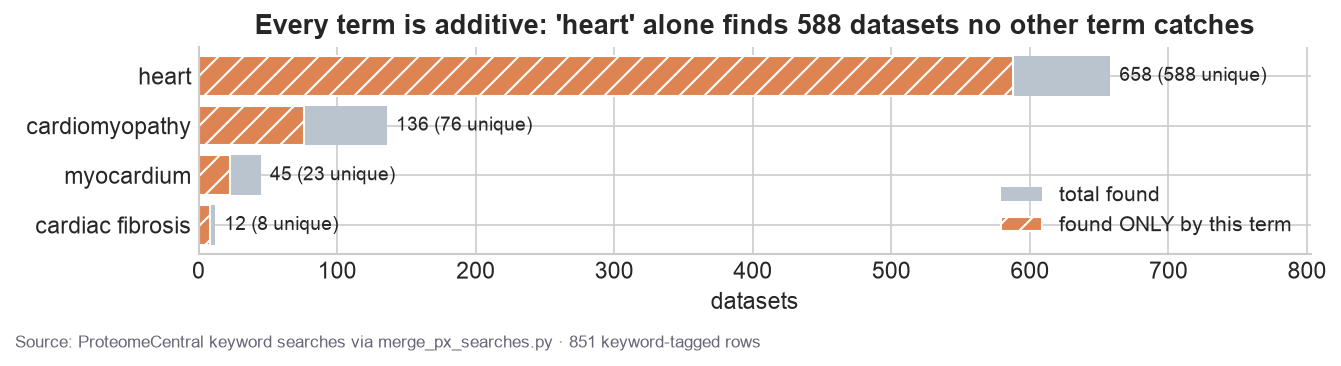

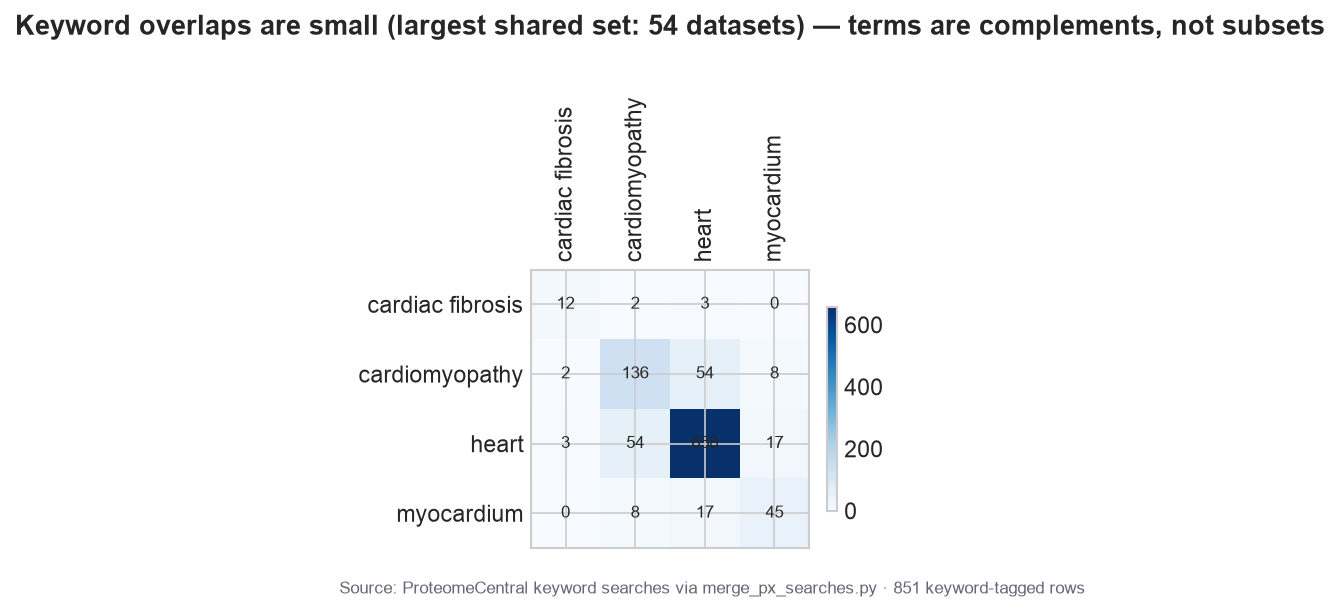

In [10]:
if EDA and "search_keyword" in raw.columns:
    per_kw = raw.groupby("search_keyword")["identifier"].agg(set)
    counts = per_kw.map(len).sort_values(ascending=False)
    uniq_only = {k: len(v - set().union(*[o for j, o in per_kw.items() if j != k]))
                 for k, v in per_kw.items()}
    top = counts.index[0]
    fig, ax = plt.subplots(figsize=(9, max(2.4, 0.55 * len(counts))))
    ax.barh(counts.index[::-1], counts[::-1], color=C_MUTED, label="total found")
    ax.barh(counts.index[::-1], [uniq_only[k] for k in counts.index[::-1]],
            color=C_ACCENT, hatch="//", edgecolor="white",
            label="found ONLY by this term")
    for yv, k in enumerate(counts.index[::-1]):
        ax.text(counts[k] + max(counts) * 0.01, yv,
                f"{counts[k]:,} ({uniq_only[k]:,} unique)", va="center", fontsize=9)
    ax.set_xlim(0, max(counts) * 1.22)
    ax.set_xlabel("datasets"); style_ax(ax); ax.legend(loc="lower right")
    ax.set_title(f"Every term is additive: '{top}' alone finds "
                 f"{uniq_only[top]:,} datasets no other term catches")
    foot(fig); fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(EDA_OUT / "01_keyword_coverage.png", dpi=150); plt.show()
    CAPTIONS.append(("01_keyword_coverage.png",
        f"Horizontal bars per search keyword: total datasets found (grey) and the "
        f"hatched-orange portion found by no other term; '{top}' contributes "
        f"{uniq_only[top]:,} unique of {counts[top]:,}."))

    kws = list(per_kw.index)
    co = pd.DataFrame([[len(per_kw[a] & per_kw[b]) for b in kws] for a in kws],
                      index=kws, columns=kws)
    fig, ax = plt.subplots(figsize=(1 + 0.7*len(kws), 1 + 0.7*len(kws)))
    im = ax.matshow(co, cmap="Blues")
    ax.set_xticks(range(len(kws)), kws, rotation=90)
    ax.set_yticks(range(len(kws)), kws)
    for i in range(len(kws)):
        for j in range(len(kws)):
            ax.text(j, i, co.iloc[i, j], ha="center", va="center", fontsize=8)
    off = co.values.copy(); off[range(len(kws)), range(len(kws))] = 0
    ax.set_title(f"Keyword overlaps are small (largest shared set: {off.max()} "
                 "datasets) — terms are complements, not subsets", pad=30)
    fig.colorbar(im, shrink=0.7); foot(fig); fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(EDA_OUT / "02_keyword_cooccurrence.png", dpi=150); plt.show()
    CAPTIONS.append(("02_keyword_cooccurrence.png",
        f"Annotated matrix of datasets shared between keyword searches; diagonal = "
        f"each term's total, largest off-diagonal overlap = {off.max()}."))
    co.to_csv(EDA_OUT / "keyword_cooccurrence.tsv", sep="\t")

## II.3 SDRF curation reach — overall, per keyword, per repository, over time

The audit's first headline numbers. Note these SDRFs are **community-curated**
(BigBio), so the rate measures curation *reach*, not submitter compliance.

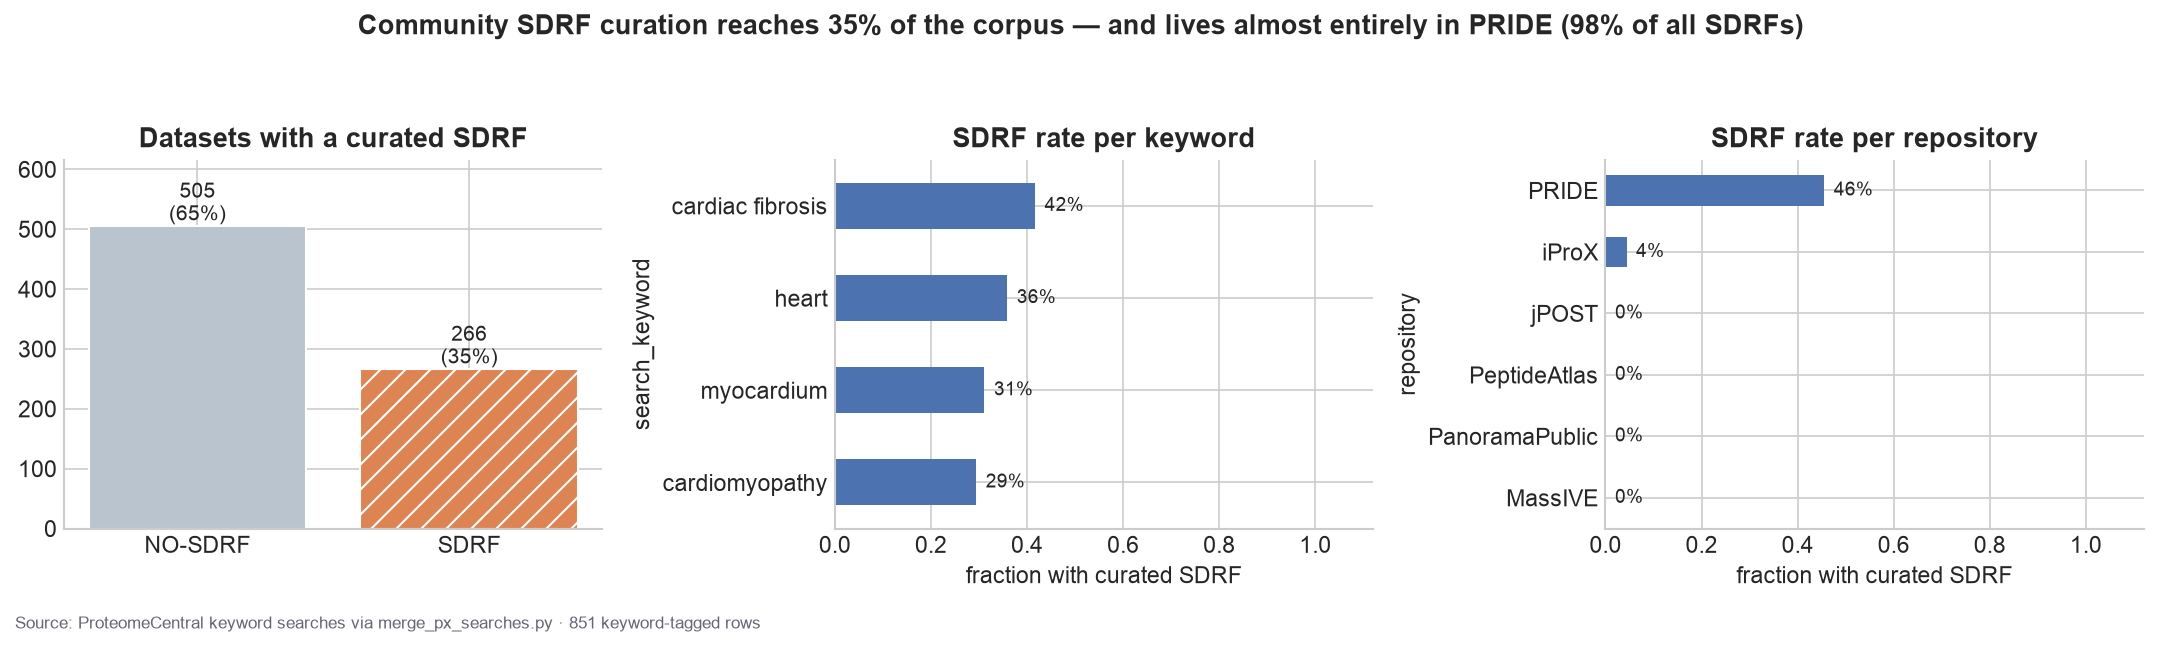

No recoverable years — skipping the growth figure. (Re-merge with the raw_row-aware merge_px_searches.py to fix.)


In [11]:
if EDA:
    pct = (df.SDRF_Found == "SDRF").mean()
    top_repo = (df[df.SDRF_Found == "SDRF"].repository.value_counts(normalize=True))
    fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))
    vc = df.SDRF_Found.value_counts()
    bars = axes[0].bar(vc.index, vc.values,
                       color=[C_MUTED if k == "NO-SDRF" else C_ACCENT for k in vc.index],
                       hatch=["" if k == "NO-SDRF" else "//" for k in vc.index],
                       edgecolor="white")
    for b, v in zip(bars, vc.values):
        axes[0].text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v/len(df):.0%})",
                     ha="center", va="bottom", fontsize=10)
    axes[0].set_ylim(0, vc.max() * 1.22); axes[0].set_title("Datasets with a curated SDRF")
    r1 = raw.groupby(kw_col).SDRF_Found.apply(lambda s: (s == "SDRF").mean()).sort_values()
    r1.plot.barh(ax=axes[1], color=C_MAIN, title="SDRF rate per keyword")
    for yv, v in enumerate(r1.values):
        axes[1].text(v + 0.02, yv, f"{v:.0%}", va="center", fontsize=9)
    r2 = df.groupby("repository").SDRF_Found.apply(lambda s: (s == "SDRF").mean()).sort_values()
    r2.plot.barh(ax=axes[2], color=C_MAIN, title="SDRF rate per repository")
    for yv, v in enumerate(r2.values):
        axes[2].text(v + 0.02, yv, f"{v:.0%}", va="center", fontsize=9)
    for a in axes[1:]: a.set_xlim(0, 1.12); a.set_xlabel("fraction with curated SDRF")
    for a in axes: style_ax(a)
    fig.suptitle(f"Community SDRF curation reaches {pct:.0%} of the corpus — "
                 f"and lives almost entirely in {top_repo.index[0]} "
                 f"({top_repo.iloc[0]:.0%} of all SDRFs)",
                 fontsize=13, fontweight="bold")
    foot(fig); fig.tight_layout(rect=(0, 0.03, 1, 0.92))
    fig.savefig(EDA_OUT / "03_sdrf_reach.png", dpi=150); plt.show()
    CAPTIONS.append(("03_sdrf_reach.png",
        f"Three panels: SDRF vs NO-SDRF counts ({pct:.0%} curated), SDRF rate per "
        f"keyword, and per repository — {top_repo.index[0]} holds "
        f"{top_repo.iloc[0]:.0%} of curated SDRFs."))

    byyear = (df.dropna(subset=["year"]).groupby("year")
                .agg(n=("identifier", "size"),
                     sdrf_rate=("SDRF_Found", lambda s: (s == "SDRF").mean())))
if EDA and len(byyear) == 0:
    print("No recoverable years — skipping the growth figure. "
          "(Re-merge with the raw_row-aware merge_px_searches.py to fix.)")
if EDA and len(byyear):
    fig, ax1 = plt.subplots(figsize=(10, 4.2))
    ax1.bar(byyear.index, byyear.n, color=C_MAIN, alpha=0.75)
    ax1.set_ylabel("datasets announced"); ax1.set_xlabel("year"); style_ax(ax1)
    ax2 = ax1.twinx()
    ax2.plot(byyear.index, byyear.sdrf_rate, marker="o", linestyle="--",
             color=C_ACCENT, linewidth=2)
    ax2.set_ylabel("fraction with curated SDRF", color=C_ACCENT)
    ax2.set_ylim(0, 1); ax2.spines["top"].set_visible(False)
    ax2.annotate("SDRF fraction", (byyear.index[-1], byyear.sdrf_rate.iloc[-1]),
                 textcoords="offset points", xytext=(6, 8), color=C_ACCENT,
                 fontsize=10, fontweight="bold")
    peak = byyear.n.idxmax()
    ax1.set_title(f"The cardiac-keyword corpus is accelerating (peak {int(peak)}: "
                  f"{int(byyear.n.max())} datasets) while SDRF curation plateaus "
                  f"below {byyear.sdrf_rate.max():.0%}")
    foot(fig, "dual axis: bars = counts (left), dashed line = SDRF fraction (right)")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.savefig(EDA_OUT / "04_growth_and_sdrf_by_year.png", dpi=150)
    plt.show()
    CAPTIONS.append(("04_growth_and_sdrf_by_year.png",
        f"Bars: datasets announced per year (peak {int(byyear.n.max())} in "
        f"{int(peak)}); dashed orange line: fraction with curated SDRF, "
        f"never exceeding {byyear.sdrf_rate.max():.0%}."))

## II.4 Who, where, and with what — species, repositories, instruments,
publication linkage

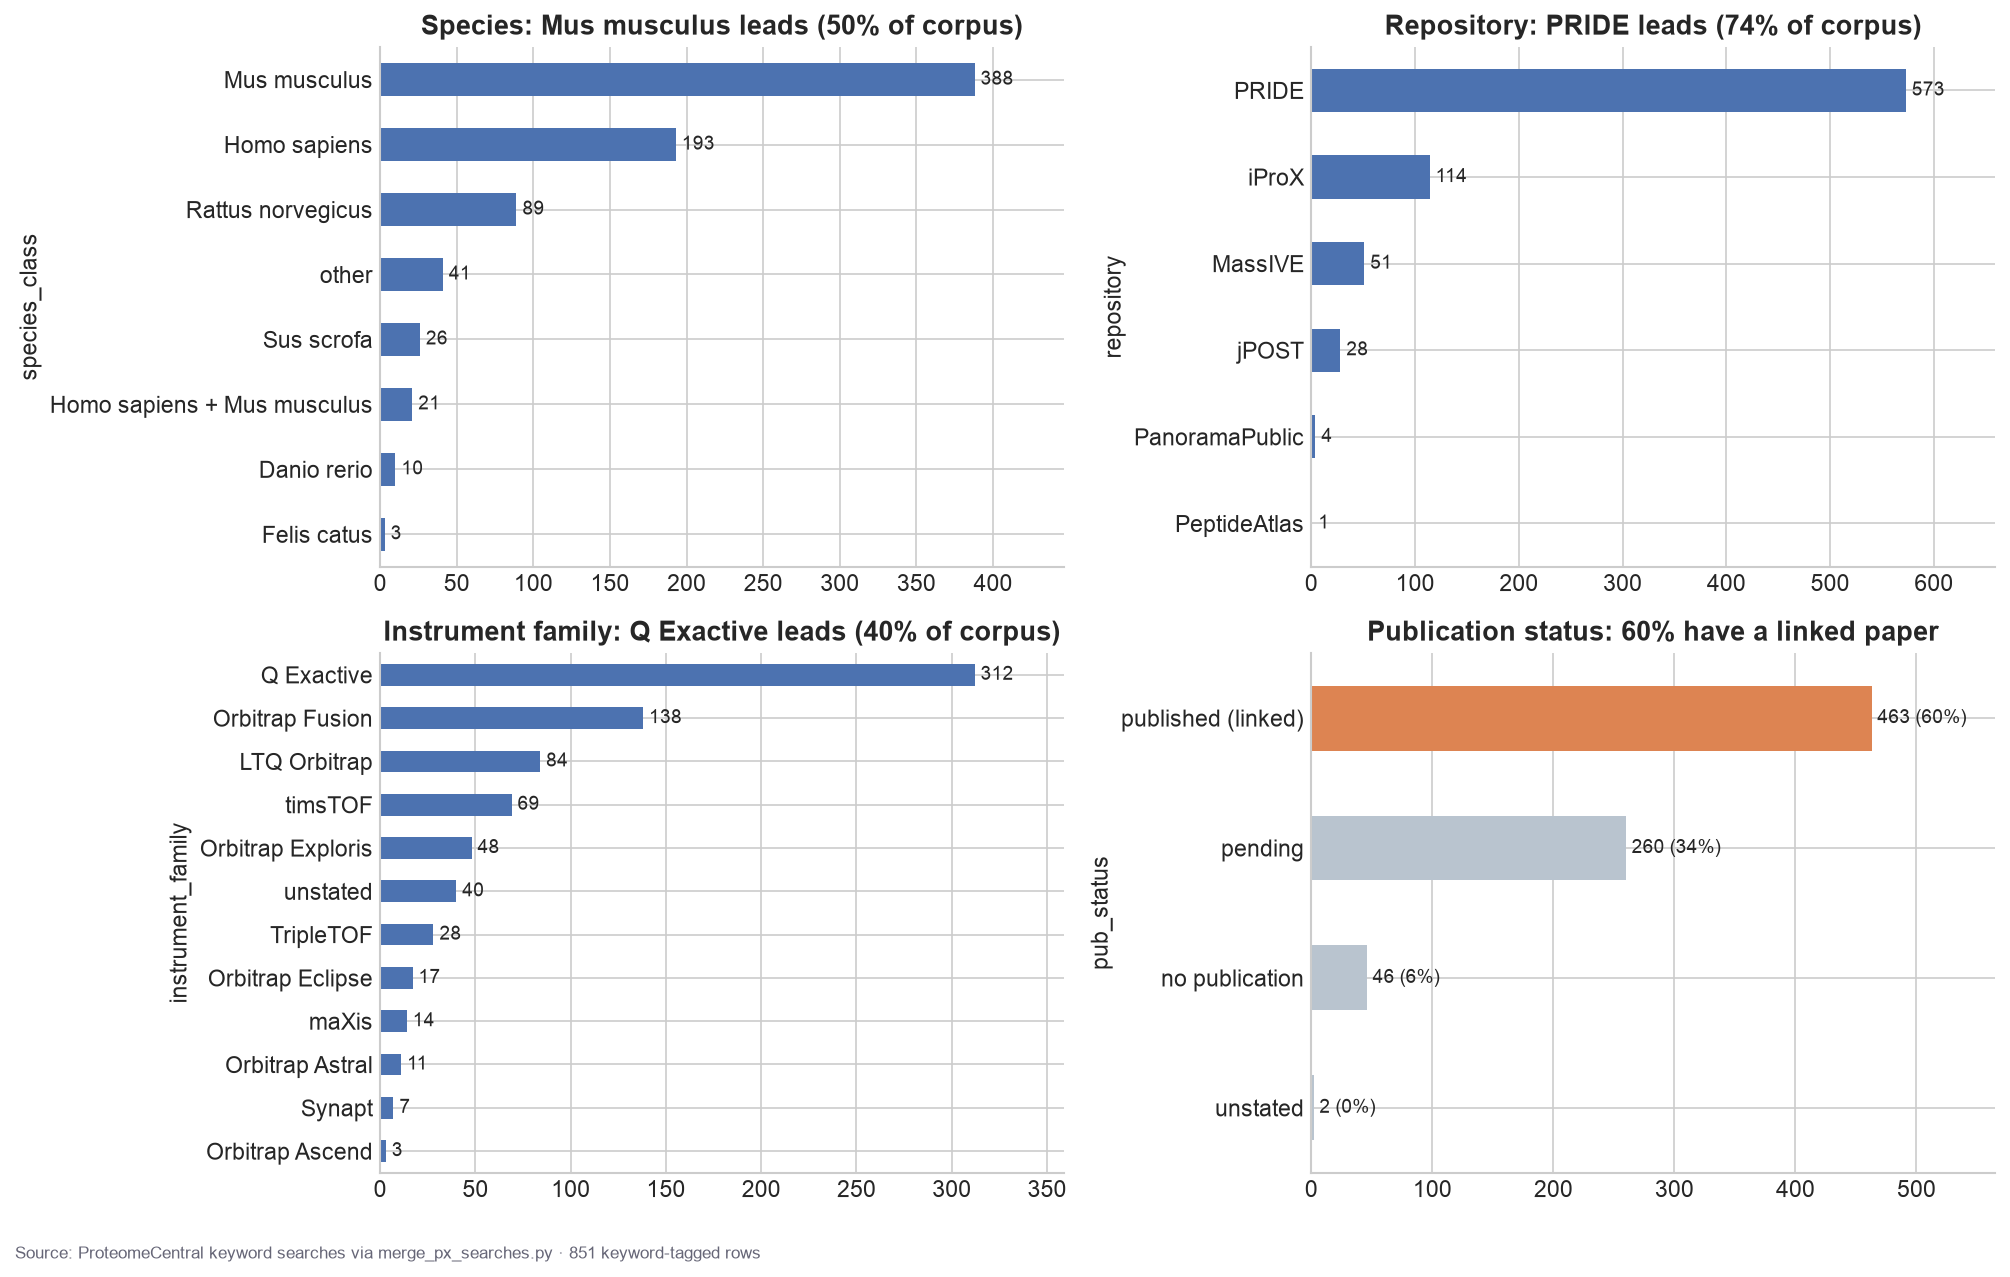

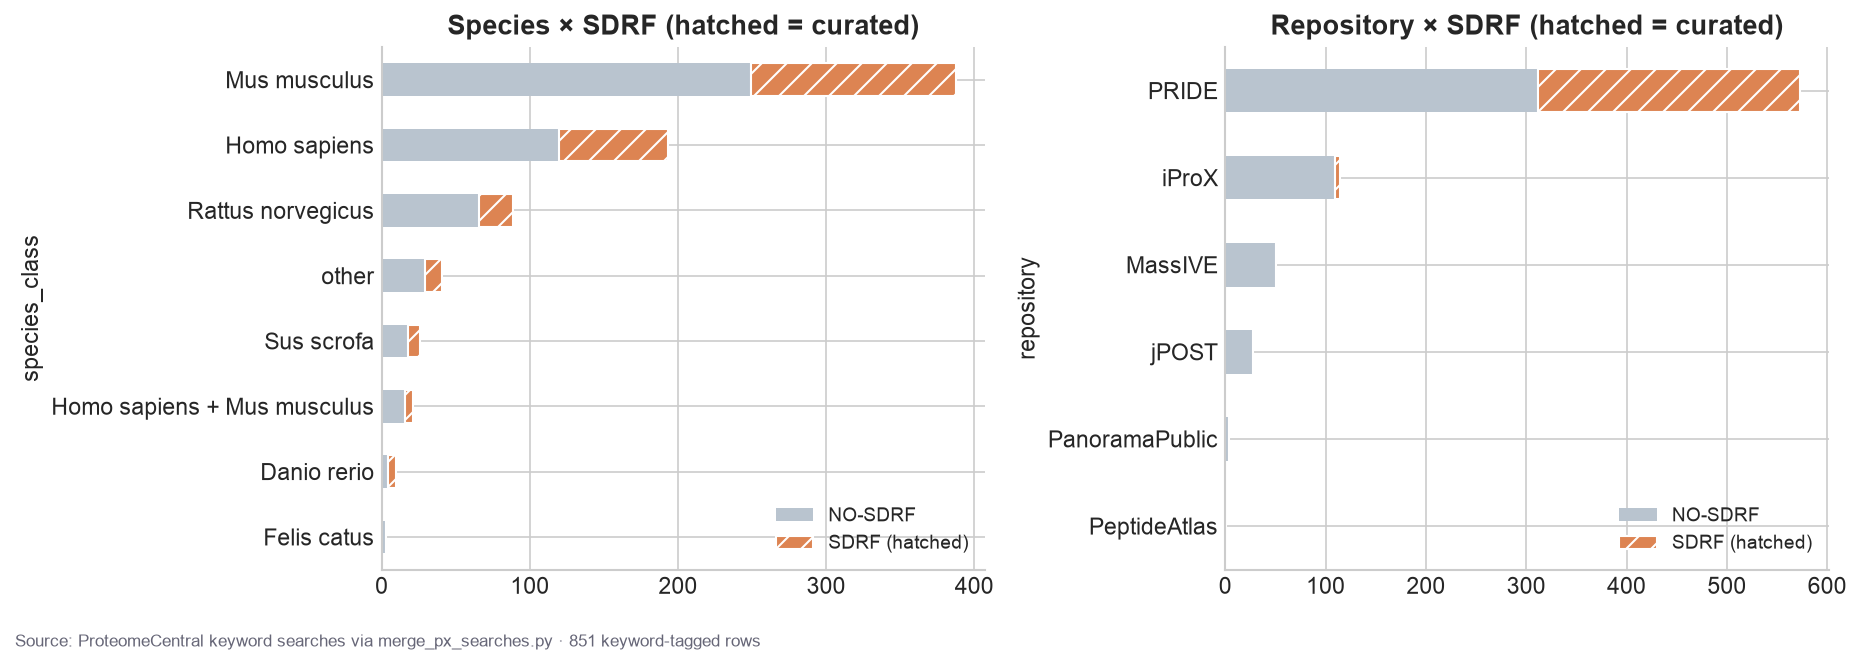

In [12]:
if EDA:
    fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.5))
    for ax, series, ttl in ((axes[0, 0], df.species_class.value_counts(), "Species"),
                            (axes[0, 1], df.repository.value_counts(), "Repository"),
                            (axes[1, 0], df.instrument_family.value_counts(),
                             "Instrument family")):
        sv = series.sort_values()
        sv.plot.barh(ax=ax, color=C_MAIN)
        for yv, v in enumerate(sv.values):
            ax.text(v + sv.max() * 0.01, yv, f"{v:,}", va="center", fontsize=9)
        ax.set_xlim(0, sv.max() * 1.15); style_ax(ax)
        ax.set_title(f"{ttl}: {series.index[0]} leads "
                     f"({series.iloc[0]/len(df):.0%} of corpus)")
    ps = df.pub_status.value_counts().sort_values()
    bars = ps.plot.barh(ax=axes[1, 1],
                        color=[C_ACCENT if k == "published (linked)" else C_MUTED
                               for k in ps.index])
    for yv, v in enumerate(ps.values):
        axes[1, 1].text(v + ps.max() * 0.01, yv, f"{v:,} ({v/len(df):.0%})",
                        va="center", fontsize=9)
    axes[1, 1].set_xlim(0, ps.max() * 1.22); style_ax(axes[1, 1])
    pubpct = (df.pub_status == "published (linked)").mean()
    axes[1, 1].set_title(f"Publication status: {pubpct:.0%} have a linked paper")
    foot(fig); fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(EDA_OUT / "05_landscape.png", dpi=150); plt.show()
    CAPTIONS.append(("05_landscape.png",
        f"Four panels: species ({df.species_class.value_counts().index[0]} leads), "
        f"repository ({df.repository.value_counts().index[0]} leads), instrument "
        f"family, and publication status ({pubpct:.0%} with a linked paper; "
        f"status derived from row content, not the shifted announce_date column)."))

    ct = pd.crosstab(df.species_class, df.SDRF_Found)
    ct.to_csv(EDA_OUT / "species_x_sdrf.tsv", sep="\t")
    ct2 = pd.crosstab(df.repository, df.SDRF_Found)
    ct2.to_csv(EDA_OUT / "repository_x_sdrf.tsv", sep="\t")
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
    for ax, c, ttl in ((axes[0], ct, "Species"), (axes[1], ct2, "Repository")):
        c = c.loc[c.sum(axis=1).sort_values().index]
        c.plot.barh(stacked=True, ax=ax, color=[C_MUTED, C_ACCENT])
        for patch, col in zip(ax.patches[len(c):], ["//"] * len(c)):
            patch.set_hatch(col); patch.set_edgecolor("white")
        ax.set_title(f"{ttl} × SDRF (hatched = curated)"); style_ax(ax)
        ax.legend(["NO-SDRF", "SDRF (hatched)"], loc="lower right", fontsize=9)
    foot(fig); fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.savefig(EDA_OUT / "06_crosstabs.png", dpi=150); plt.show()
    CAPTIONS.append(("06_crosstabs.png",
        "Stacked bars of SDRF (hatched orange) vs NO-SDRF (grey) by species class "
        "and by repository, sorted by total."))

## II.5 Summary snapshot

Everything above, as numbers, written to `out/eda/summary.md` — the quotable
corpus-description paragraph (IPA-safe: descriptions, not analyzed results).

In [13]:
if EDA:
    lines = [
        "# Corpus EDA summary", "",
        f"- unique datasets: **{len(df)}** (from {len(raw)} keyword-tagged rows)",
        f"- SDRF (community-curated): **{sum(df.SDRF_Found=='SDRF')}** "
        f"({(df.SDRF_Found=='SDRF').mean():.1%})",
        f"- repositories: " + ", ".join(f"{k} {v}" for k, v in df.repository.value_counts().items()),
        f"- species classes: " + ", ".join(f"{k} {v}" for k, v in df.species_class.value_counts().items()),
        f"- year span: {span} (year recoverable for {df.year.notna().mean():.1%})",
        f"- publication status: " + ", ".join(
            f"{k} {v}" for k, v in df.pub_status.value_counts().items()),
        "", "Figures: " + ", ".join(sorted(p.name for p in EDA_OUT.glob('*.png'))),
    ]
    (EDA_OUT / "summary.md").write_text("\n".join(lines), encoding="utf-8")
    (EDA_OUT / "fig_captions.md").write_text(
        "# Figure alt-text / captions\n\n" +
        "\n".join(f"- **{f}** — {c}" for f, c in CAPTIONS), encoding="utf-8")
    print("\n".join(lines))
    print(f"\nwrote {EDA_OUT/'fig_captions.md'} ({len(CAPTIONS)} captions)")

# Corpus EDA summary

- unique datasets: **771** (from 851 keyword-tagged rows)
- SDRF (community-curated): **266** (34.5%)
- repositories: PRIDE 573, iProX 114, MassIVE 51, jPOST 28, PanoramaPublic 4, PeptideAtlas 1
- species classes: Mus musculus 388, Homo sapiens 193, Rattus norvegicus 89, other 41, Sus scrofa 26, Homo sapiens + Mus musculus 21, Danio rerio 10, Felis catus 3
- year span: n/a (year recoverable for 0.0%)
- publication status: published (linked) 463, pending 260, no publication 46, unstated 2

Figures: 01_keyword_coverage.png, 02_keyword_cooccurrence.png, 03_sdrf_reach.png, 04_growth_and_sdrf_by_year.png, 05_landscape.png, 06_crosstabs.png

wrote out/eda/fig_captions.md (5 captions)
